# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

current_dir = os.path.dirname(os.path.abspath("Incremental-Learning-MycroftMinds"))
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

## Import external libs and internal models

In [2]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_splits_seq_fit_predict

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(649, 43), y=(649,)
First valid split shape: X=(672, 43), y=(672,)

Memory usage:
Train: 6.26 MB
Valid: 1.41 MB
Test: 0.41 MB
Total: 8.08 MB


# Model evaluation

## Hourly granularity

### Baseline model (predict previous value)

In [7]:
device_period_metrics = {}
for split in valid:
    for device_id in set(split[0][:, 1]):  # Assuming device_id is in the second column
        X_valid, y_valid = get_device_data(split, device_id=device_id)
        y_pred = y_valid.shift(1)
        y_pred.iloc[0] = y_valid.iloc[0]
        
        device_metrics = calculate_metrics(
            y_valid,
            y_pred,
            device_id,
            f"{X_valid[0, 0]} - {X_valid[-1, 0]}", 
            verbose=True
            )
        
        if device_id not in device_period_metrics:
            device_period_metrics[device_id] = []
        device_period_metrics[device_id].append(device_metrics)

Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2534
	MAE: 0.1475
	MAPE: 17.3852%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2534
	MAE: 0.1475
	MAPE: 17.3852%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.3367
	MAE: 0.1617
	MAPE: 1.1525%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.7120
	MAE: 0.4989
	MAPE: 1.6345%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 1.0929
	MAE: 0.9782
	MAPE: 3.7520%
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2

In [8]:
all_time_metrics = all_time_aggregation_metrics(device_period_metrics, verbose=True)



Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2277 ± 0.0410
	MAE: 0.1286 ± 0.0300
	MAPE: 0.2389 ± 0.0746
Hourly Metrics:
	RMSE: 0.2277 ± 0.0410
	MAE: 0.1286 ± 0.0300
	MAPE: 0.2389 ± 0.0746
Daily Metrics:
	RMSE: 0.2346 ± 0.0854
	MAE: 0.1077 ± 0.0389
	MAPE: 0.0116 ± 0.0026
Weekly Metrics:
	RMSE: 0.5482 ± 0.1876
	MAE: 0.3715 ± 0.1347
	MAPE: 0.0149 ± 0.0059
28_days Metrics:
	RMSE: 0.8754 ± 0.3198
	MAE: 0.8377 ± 0.3049
	MAPE: 0.0330 ± 0.0145


#### Validation plots

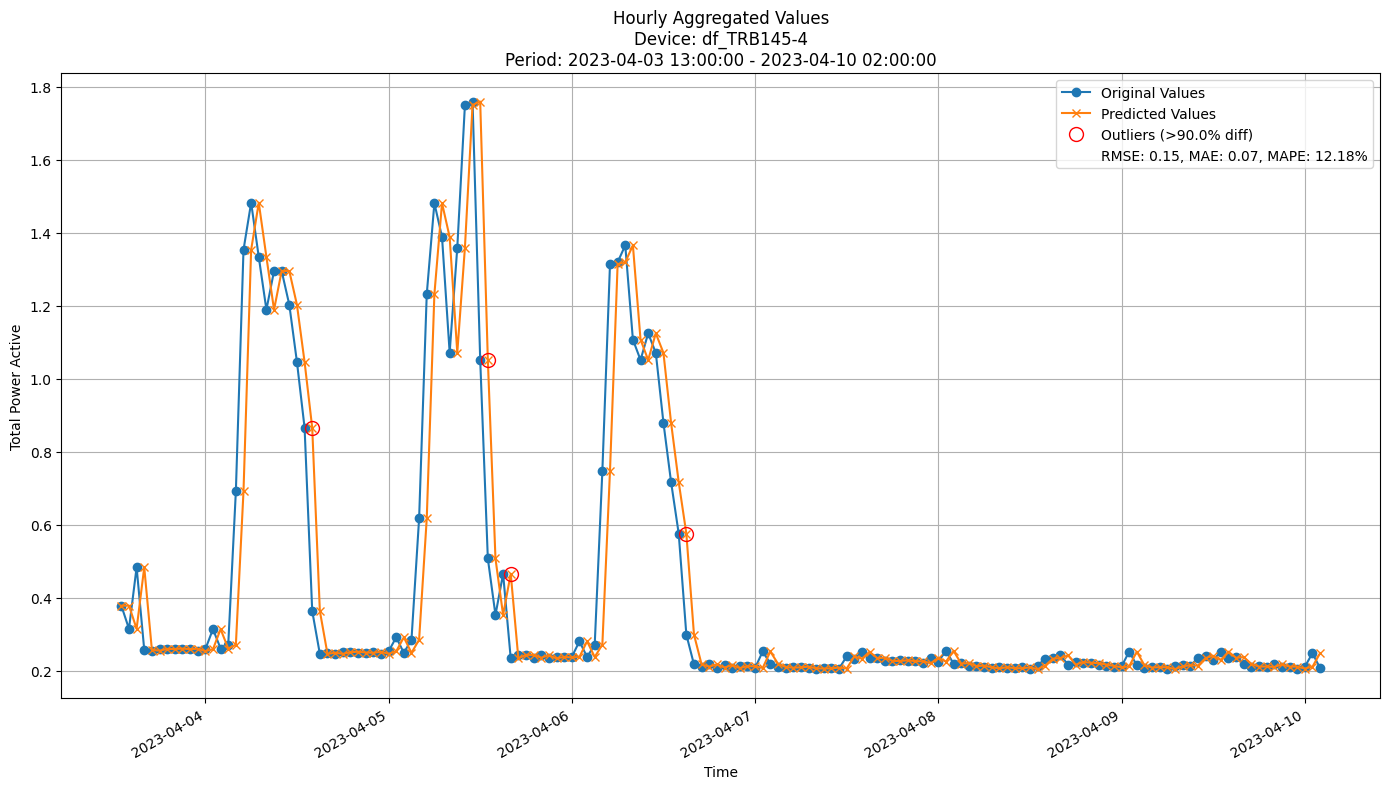

In [9]:
plot_hourly_predictions(y_valid, 
                        y_pred, 
                        device_id, 
                        outlier_threshold=0.9)

### GBDT

In [10]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.01,
    subsample=0.8,
    max_depth=6,
    random_state=42)

gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=False
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 1.83 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 2.73 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 3.72 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 4.71 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 12.00 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 13.20 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 14.08 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------


#### Results

In [11]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.1498 ± 0.0225
	MAE: 0.1031 ± 0.0135
	MAPE: 0.2142 ± 0.0301
Hourly Metrics:
	RMSE: 0.1498 ± 0.0225
	MAE: 0.1031 ± 0.0135
	MAPE: 0.2142 ± 0.0301
Daily Metrics:
	RMSE: 1.4884 ± 0.1854
	MAE: 1.2391 ± 0.1446
	MAPE: 0.1104 ± 0.0110
Weekly Metrics:
	RMSE: 4.4955 ± 1.0513
	MAE: 3.6101 ± 0.8590
	MAPE: 0.0390 ± 0.0065
28_days Metrics:
	RMSE: 14.6017 ± 5.9032
	MAE: 13.4024 ± 5.5116
	MAPE: 0.0302 ± 0.0124


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2450 ± 0.0615
	MAE: 0.1702 ± 0.0404
	MAPE: 0.3865 ± 0.0630
Hourly Metrics:
	RMSE: 0.2450 ± 0.0615
	MAE: 0.1702 ± 0.0404
	MAPE: 0.3865 ± 0.0630
Daily Metrics:
	RMSE: 2.4367 ± 0.9991
	MAE: 2.0526 ± 0.8480
	MAPE: 0.2068 ± 0.0305
Weekly Metrics:
	RMSE: 7.4718 ± 2.9125
	MAE: 5.8499 ± 2.3006


#### Feature importance
[WiP] Right now only for the last split and last device

In [12]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.5943921845500145)),
 ('hour', np.float64(0.08886917084971233)),
 ('L2_current_lag_1h', np.float64(0.07192525244996019)),
 ('L2_act_power_lag_1h', np.float64(0.07107288213260735)),
 ('L3_react_power_lag_1h', np.float64(0.036767583077128095)),
 ('month', np.float64(0.013931180942019172)),
 ('powerfactor3_lag_1h', np.float64(0.012754361992107251)),
 ('L2_app_power_lag_1h', np.float64(0.012263424677982897)),
 ('L1_app_power_lag_1h', np.float64(0.010302824449483328)),
 ('L1_act_power_lag_1h', np.float64(0.006141652915243028)),
 ('L3_act_power_lag_1h', np.float64(0.004925153490228159)),
 ('grid_freq_lag_1h', np.float64(0.0046450919333752986)),
 ('L3_react_power_lag_24h', np.float64(0.004565227564230447)),
 ('L1_react_power_lag_24h', np.float64(0.00454232057276003)),
 ('L3_app_power_lag_1h', np.float64(0.004420363660290429)),
 ('powerfactor2_lag_24h', np.float64(0.004363829136757241)),
 ('L2_act_power_lag_24h', np.float64(0.004192033404760283)),
 ('weekday'

#### Training plots
Plot only the last period of predictions

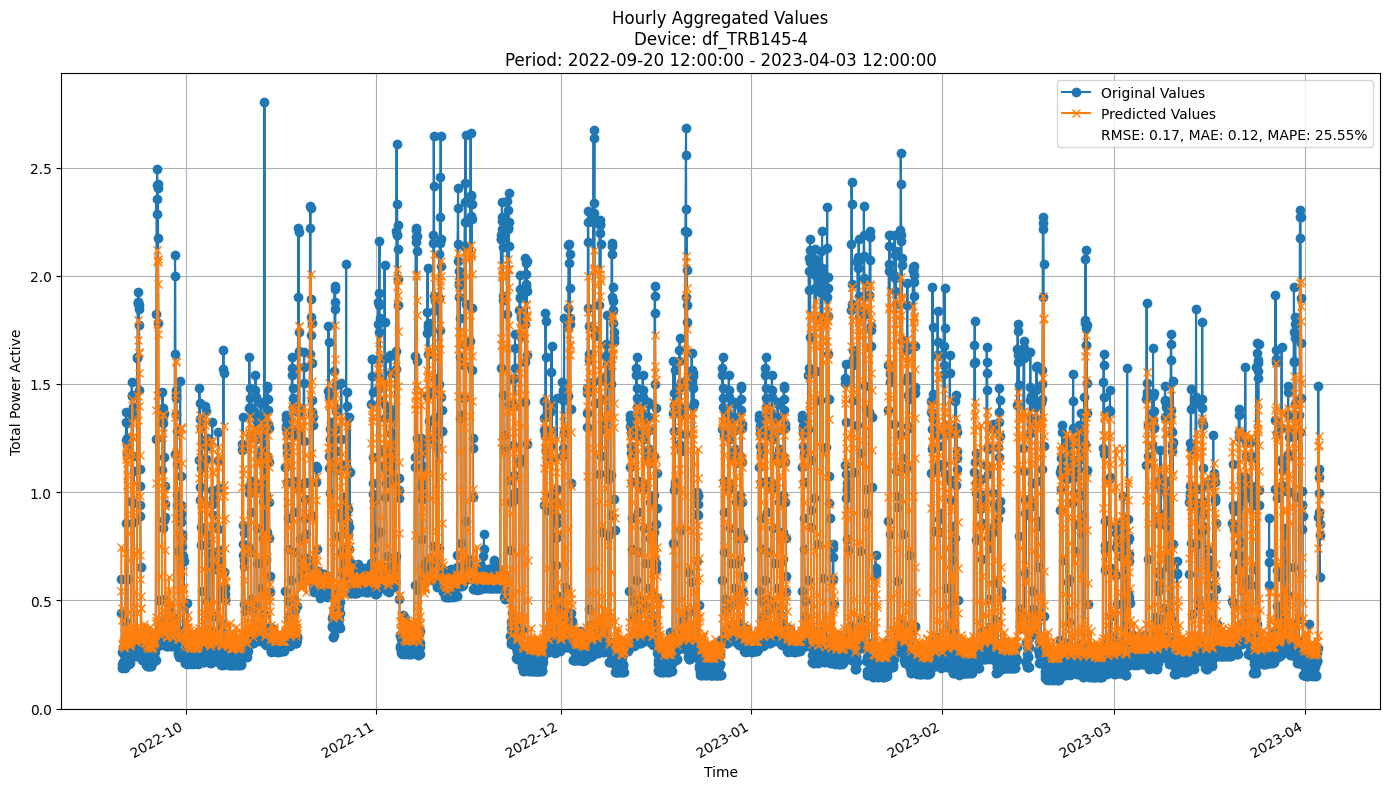

In [13]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)
# 48, 32, 61

#### Validation plots
Plot only the last period of predictions

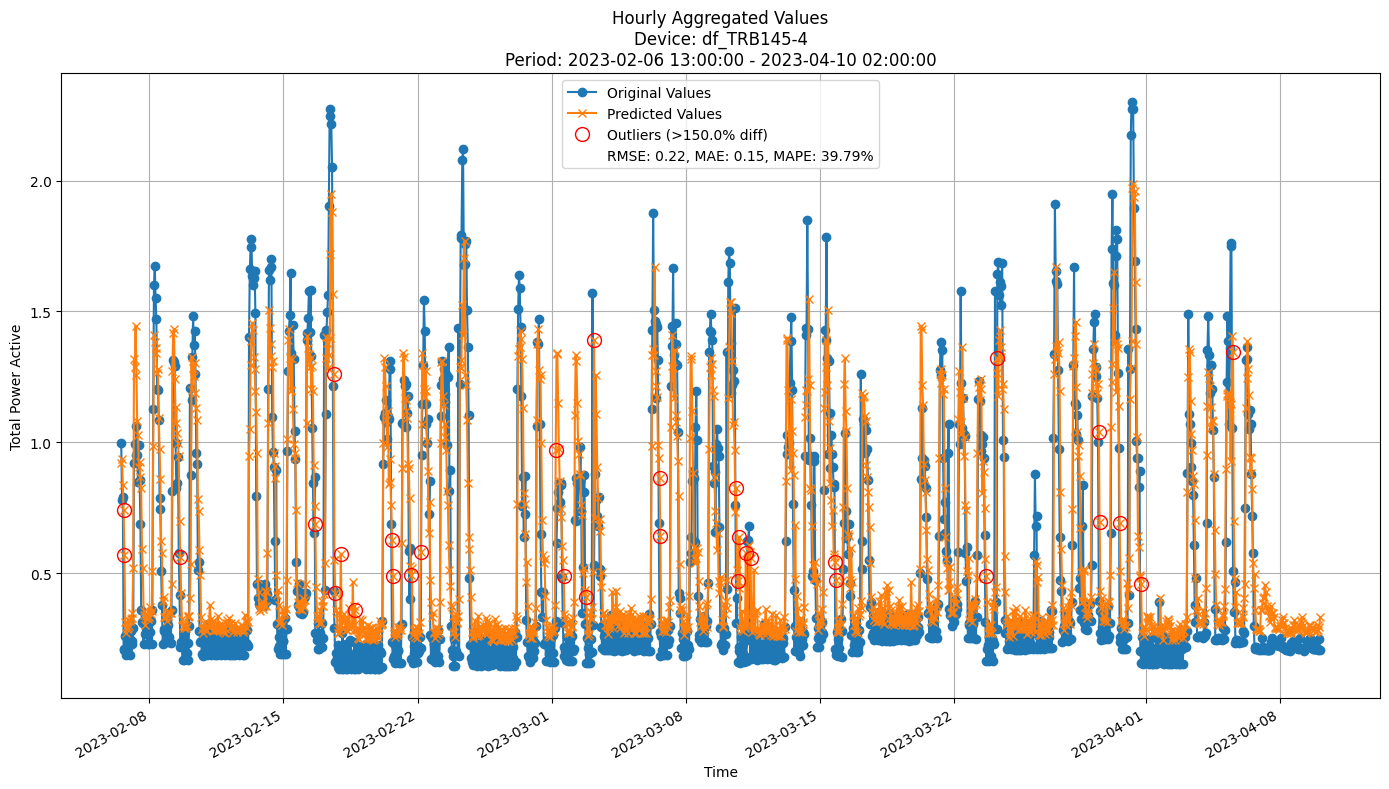

In [90]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [15]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=4,
    max_features=0.8,
    random_state=42, 
    n_jobs=-1)

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 0.16 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3245
	MAE: 0.1964
	MAPE: 21.2100%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3245
	MAE: 0.1964
	MAPE: 21.2100%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.1727
	MAE: 3.2215
	MAPE

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 0.16 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 0.17 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2865
	MAE: 0.1745
	MAPE: 29.9529%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2865
	MAE: 0.1745
	MAPE: 29.9529%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.4516
	MAE: 2.0109
	MAPE

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 0.37 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 0.44 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2385
	MAE: 0.1486
	MAPE: 32.3394%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2385
	MAE: 0.1486
	MAPE: 32.3394%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.8463
	MAE: 1.4042
	MAPE

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 0.47 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.1555
	MAE: 0.0837
	MAPE: 21.6022%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1555
	MAE: 0.0837
	MAPE: 21.6022%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.2097
	MAE: 1.0438
	MAPE: 13.9619%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 5.8558
	MAE: 4.1750
	MAPE: 11.5596%
--------------------------------------------------
28_days 

#### Results

In [16]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2221 ± 0.0148
	MAE: 0.1267 ± 0.0092
	MAPE: 0.2215 ± 0.0201
Hourly Metrics:
	RMSE: 0.2221 ± 0.0148
	MAE: 0.1267 ± 0.0092
	MAPE: 0.2215 ± 0.0201
Daily Metrics:
	RMSE: 1.7668 ± 0.1502
	MAE: 1.3197 ± 0.1091
	MAPE: 0.0984 ± 0.0053
Weekly Metrics:
	RMSE: 6.2770 ± 1.4383
	MAE: 4.8404 ± 1.0919
	MAPE: 0.0530 ± 0.0091
28_days Metrics:
	RMSE: 19.7357 ± 8.0124
	MAE: 17.9420 ± 7.0945
	MAPE: 0.0404 ± 0.0159


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2221 ± 0.0148
	MAE: 0.1267 ± 0.0092
	MAPE: 0.2215 ± 0.0201
Hourly Metrics:
	RMSE: 0.2221 ± 0.0148
	MAE: 0.1267 ± 0.0092
	MAPE: 0.2215 ± 0.0201
Daily Metrics:
	RMSE: 1.7668 ± 0.1502
	MAE: 1.3197 ± 0.1091
	MAPE: 0.0984 ± 0.0053
Weekly Metrics:
	RMSE: 6.2770 ± 1.4383
	MAE: 4.8404 ± 1.0919


#### Feature importance
[WiP] Right now only for the last split and last device

In [17]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.5762642336881951)),
 ('L1_app_power_lag_1h', np.float64(0.10568487077227992)),
 ('hour', np.float64(0.07371084921967604)),
 ('L2_current_lag_1h', np.float64(0.06284728388419433)),
 ('L2_act_power_lag_1h', np.float64(0.060075330591458746)),
 ('L3_react_power_lag_1h', np.float64(0.04234170230657086)),
 ('L1_act_power_lag_1h', np.float64(0.028437470118502218)),
 ('L2_app_power_lag_1h', np.float64(0.024095446207157485)),
 ('powerfactor3_lag_1h', np.float64(0.0029458156494507758)),
 ('month', np.float64(0.0026329251359712763)),
 ('L3_app_power_lag_1h', np.float64(0.0024065417105137645)),
 ('L3_act_power_lag_1h', np.float64(0.0022050371920968835)),
 ('L2_current_lag_24h', np.float64(0.0019331762146278337)),
 ('L1_react_power_lag_24h', np.float64(0.0018648501384058774)),
 ('L3_act_power_lag_24h', np.float64(0.001423267116350017)),
 ('L1_app_power_lag_24h', np.float64(0.0014062037837172087)),
 ('L1_act_power_lag_24h', np.float64(0.0014000363703803584)),
 ('L

#### Training plots
Plot only the last period of predictions

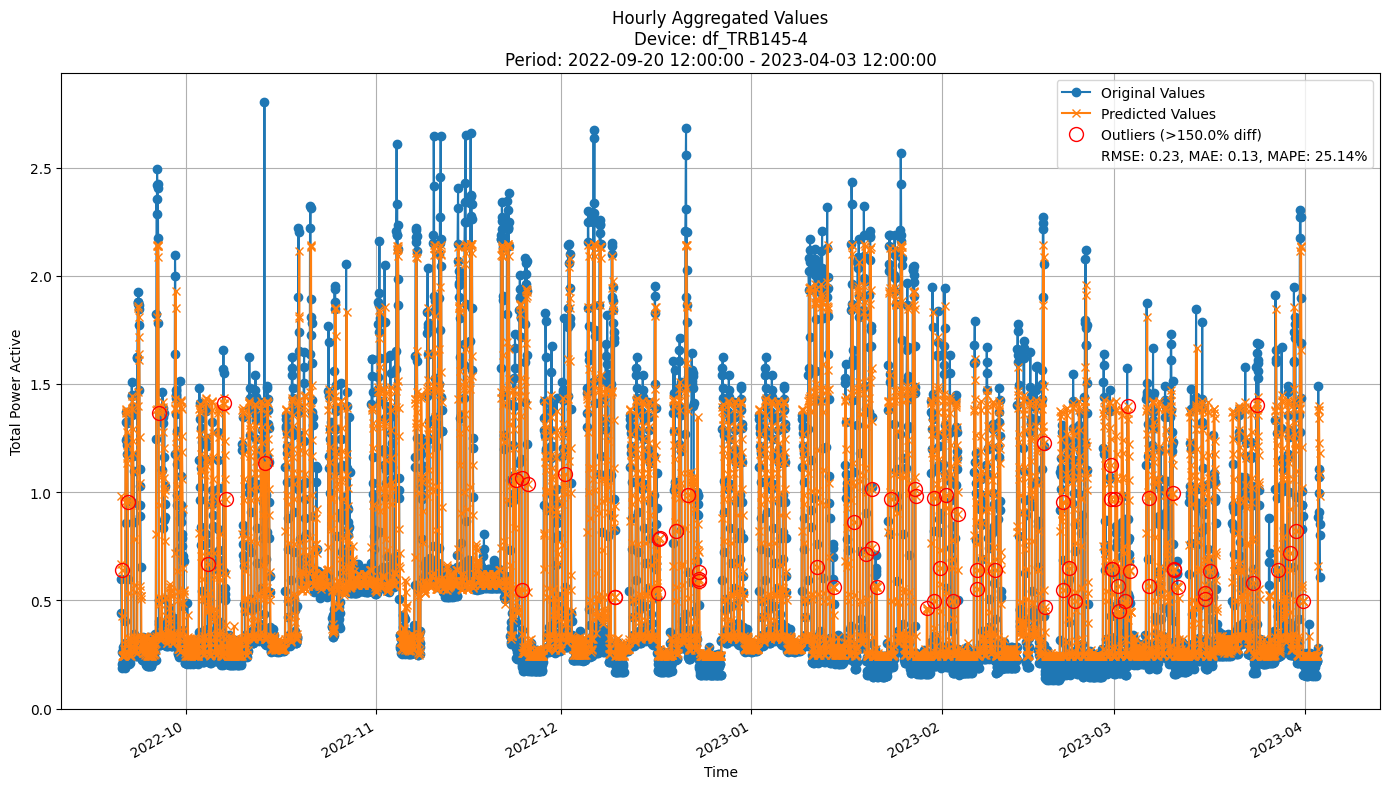

In [18]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

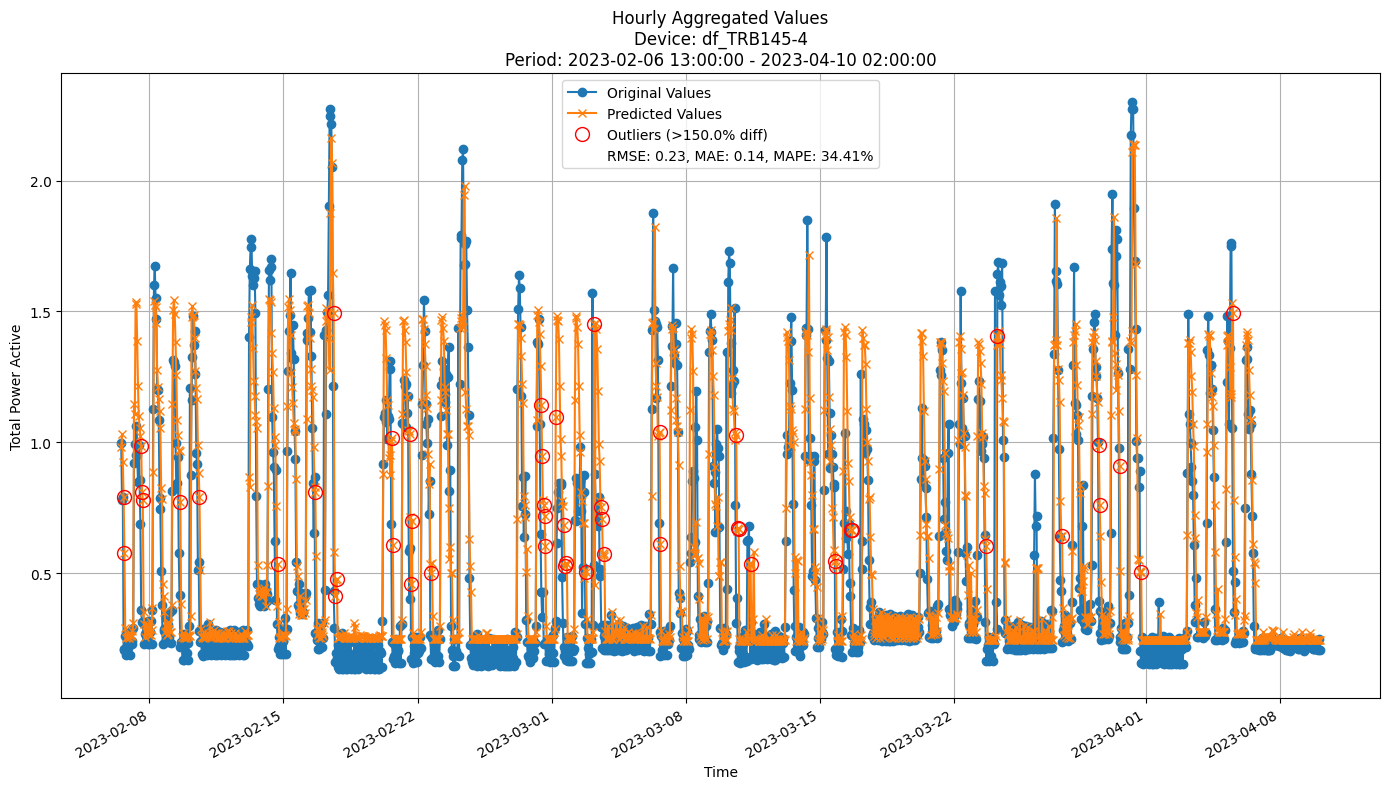

In [89]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [20]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 10
delta = 0.5
max_depth = 10
tau = 0.05

hoef = HoeffdingTreeRegressor(
        max_depth=max_depth,
        grace_period=grace_period,
        delta=delta,
        tau=tau,
        leaf_prediction="mean"
    )

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3746
	MAE: 0.2556
	MAPE: 29.1036%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3746
	MAE: 0.2556
	MAPE: 29.1036%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.1078
	MAE: 4.0082
	MAPE: 20.1554%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 21.6977
	MAE: 17.8734
	MAPE: 18.1733%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 59.0312
	MAE: 44.6835
	MAPE: 22.9713%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3566
	MAE: 0.2247
	MAPE: 33.0720%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3566
	MAE: 0.2247
	MAPE: 33.0720%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.8259
	MAE: 3.0232
	MAPE: 18.4079%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 9.4907
	MAE: 7.4224
	MAPE: 6.5978%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 25.8711
	MAE: 18.5561
	MAPE: 5.7762%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2995
	MAE: 0.1876
	MAPE: 36.9397%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2995
	MAE: 0.1876
	MAPE: 36.9397%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.7277
	MAE: 2.2248
	MAPE: 18.7581%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 11.7877
	MAE: 10.2484
	MAPE: 17.0823%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 34.1843
	MAE: 25.6209
	MAPE: 22.2038%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.1994
	MAE: 0.1174
	MAPE: 28.7214%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1994
	MAE: 0.1174
	MAPE: 28.7214%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.7537
	MAE: 1.5365
	MAPE: 24.9960%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 5.9390
	MAE: 4.3335
	MAPE: 26.9448%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 8.6670
	MAE: 8.6670
	MAPE: 13.2255%


#### Results

In [78]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2769 ± 0.0336
	MAE: 0.1652 ± 0.0247
	MAPE: 0.2846 ± 0.0570
Hourly Metrics:
	RMSE: 0.2769 ± 0.0336
	MAE: 0.1652 ± 0.0247
	MAPE: 0.2846 ± 0.0570
Daily Metrics:
	RMSE: 2.6302 ± 0.6186
	MAE: 2.0575 ± 0.5088
	MAPE: 0.1467 ± 0.0449
Weekly Metrics:
	RMSE: 9.0415 ± 1.6558
	MAE: 7.2159 ± 1.3220
	MAPE: 0.0792 ± 0.0189
28_days Metrics:
	RMSE: 27.6639 ± 10.4680
	MAE: 25.8932 ± 9.6501
	MAPE: 0.0615 ± 0.0218


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2930 ± 0.0571
	MAE: 0.1852 ± 0.0426
	MAPE: 0.3355 ± 0.0450
Hourly Metrics:
	RMSE: 0.2930 ± 0.0571
	MAE: 0.1852 ± 0.0426
	MAPE: 0.3355 ± 0.0450
Daily Metrics:
	RMSE: 3.0080 ± 1.0678
	MAE: 2.3872 ± 0.8064
	MAPE: 0.1886 ± 0.0370
Weekly Metrics:
	RMSE: 11.1843 ± 5.1417
	MAE: 8.9962 ± 4.283

#### Training plots
Plot only the last period of predictions

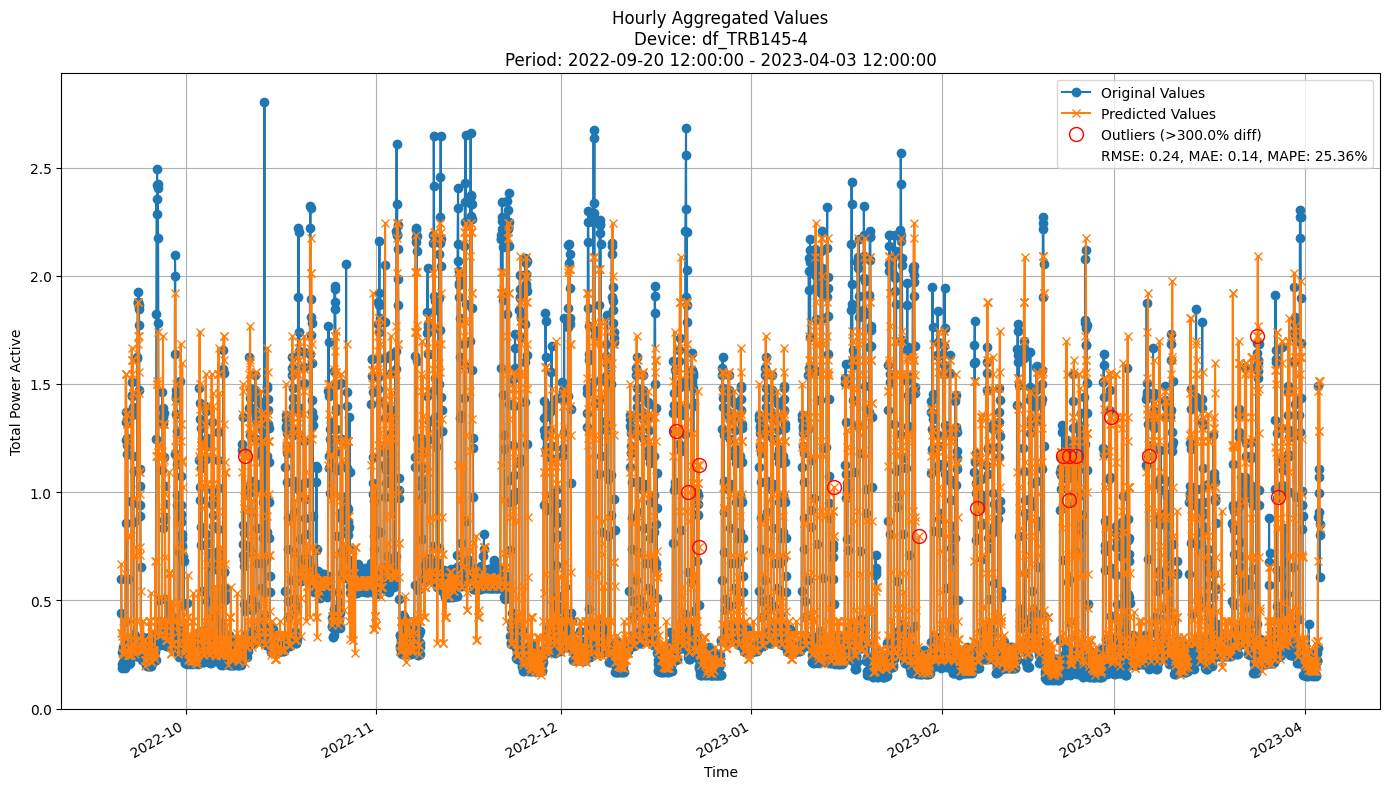

In [22]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

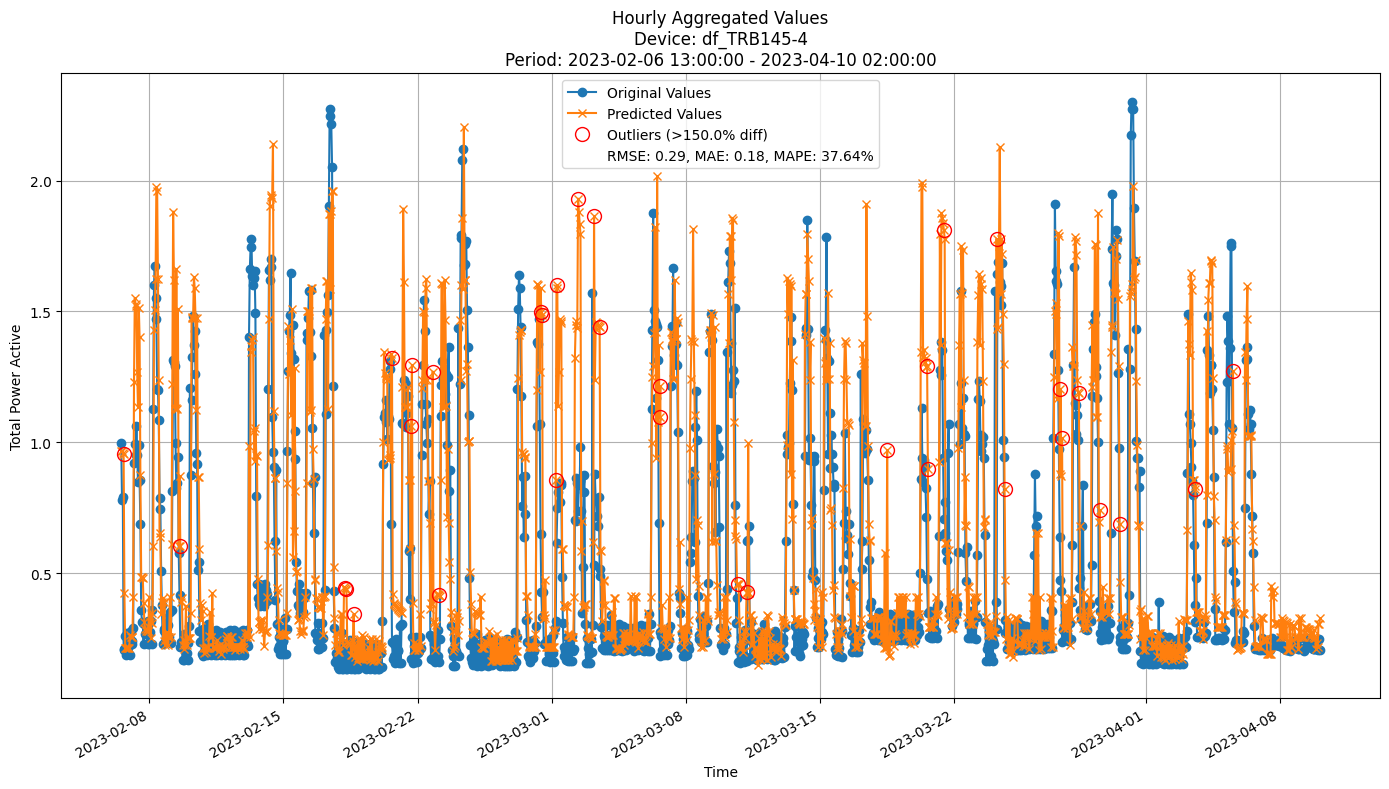

In [88]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [24]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3631
	MAE: 0.2355
	MAPE: 27.3743%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3631
	MAE: 0.2355
	MAPE: 27.3743%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.4454
	MAE: 4.2911
	MAPE: 22.1976%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 18.9809
	MAE: 17.0045
	MAPE: 18.9849%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 55.0597
	MAE: 42.5113
	MAPE: 26.0242%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3245
	MAE: 0.2214
	MAPE: 39.9123%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3245
	MAE: 0.2214
	MAPE: 39.9123%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.9443
	MAE: 3.1778
	MAPE: 23.2682%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 9.8262
	MAE: 6.0751
	MAPE: 5.7340%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 20.5947
	MAE: 14.9323
	MAPE: 5.9889%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2498
	MAE: 0.1676
	MAPE: 37.3576%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2498
	MAE: 0.1676
	MAPE: 37.3576%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.3846
	MAE: 1.9652
	MAPE: 18.5437%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.8421
	MAE: 9.6257
	MAPE: 13.3548%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 33.1137
	MAE: 24.0643
	MAPE: 13.3676%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.1904
	MAE: 0.1279
	MAPE: 40.8609%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1904
	MAE: 0.1279
	MAPE: 40.8609%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.2832
	MAE: 1.8568
	MAPE: 33.6604%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.2775
	MAE: 7.4273
	MAPE: 35.5236%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 14.8546
	MAE: 14.8546
	MAPE: 22.6675%


#### Results

In [25]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2586 ± 0.0565
	MAE: 0.1637 ± 0.0445
	MAPE: 0.3161 ± 0.1112
Hourly Metrics:
	RMSE: 0.2586 ± 0.0565
	MAE: 0.1637 ± 0.0445
	MAPE: 0.3161 ± 0.1112
Daily Metrics:
	RMSE: 3.1903 ± 0.9528
	MAE: 2.4899 ± 0.8054
	MAPE: 0.2056 ± 0.0956
Weekly Metrics:
	RMSE: 11.5828 ± 2.9687
	MAE: 9.4155 ± 2.8194
	MAPE: 0.1067 ± 0.0390
28_days Metrics:
	RMSE: 38.9085 ± 18.8850
	MAE: 35.8407 ± 18.6605
	MAPE: 0.0816 ± 0.0434

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.2648 ± 0.0614
	MAE: 0.1745 ± 0.0421
	MAPE: 0.3638 ± 0.0667
Hourly Metrics:
	RMSE: 0.2648 ± 0.0614
	MAE: 0.1745 ± 0.0421
	MAPE: 0.3638 ± 0.0667
Daily Metrics:
	RMSE: 3.1084 ± 1.1922
	MAE: 2.5123 ± 0.9030
	MAPE: 0.2263 ± 0.0617
Weekly Metrics:
	RMSE: 11.9660 ± 4.0432
	MAE: 9.5484 ± 3.9

#### Training plots
Plot only the last period of predictions

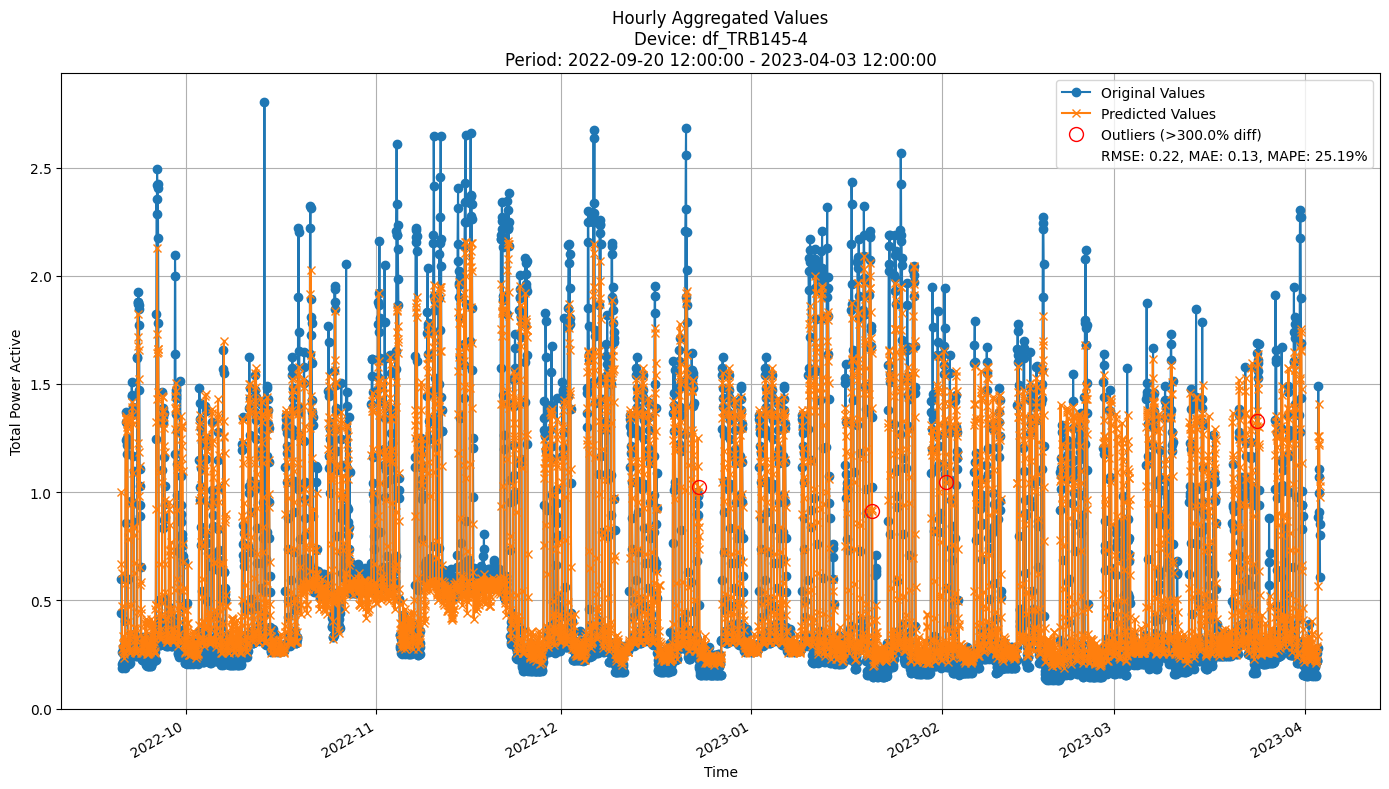

In [26]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

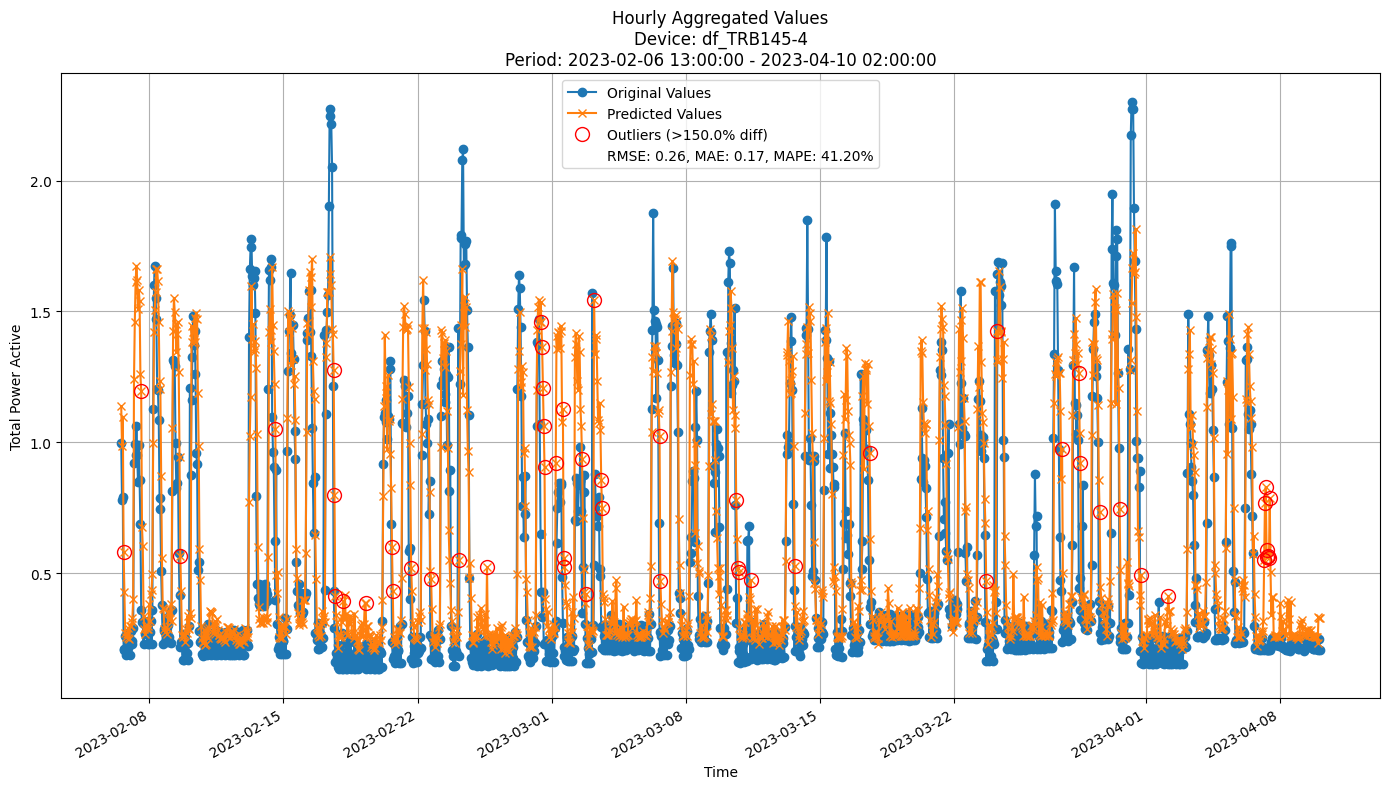

In [87]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [28]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.5
depth = 20
fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf'
    )

fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.5477
	MAE: 0.3932
	MAPE: 41.1646%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5477
	MAE: 0.3932
	MAPE: 41.1646%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 10.0525
	MAE: 8.4902
	MAPE: 39.4193%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 50.3153
	MAE: 46.1173
	MAPE: 42.8644%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 155.2396
	MAE: 115.2932
	MAPE: 48.4821%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.6180
	MAE: 0.4235
	MAPE: 55.4238%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.6180
	MAE: 0.4235
	MAPE: 55.4238%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 10.3571
	MAE: 8.7843
	MAPE: 53.2164%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 42.2745
	MAE: 37.3611
	MAPE: 33.6507%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 129.7395
	MAE: 93.4028
	MAPE: 31.9573%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3473
	MAE: 0.2410
	MAPE: 55.9541%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3473
	MAE: 0.2410
	MAPE: 55.9541%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.5435
	MAE: 3.8218
	MAPE: 39.4224%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 6.4627
	MAE: 4.3301
	MAPE: 6.8500%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 12.6764
	MAE: 9.5543
	MAPE: 8.8231%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3071
	MAE: 0.2293
	MAPE: 73.4515%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3071
	MAE: 0.2293
	MAPE: 73.4515%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.2203
	MAE: 3.5080
	MAPE: 60.0027%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 8.4805
	MAE: 6.1279
	MAPE: 29.1954%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 12.2558
	MAE: 12.2558
	MAPE: 18.7018%


#### Results

In [29]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4763 ± 0.0427
	MAE: 0.3215 ± 0.0321
	MAPE: 0.5183 ± 0.0427
Hourly Metrics:
	RMSE: 0.4763 ± 0.0427
	MAE: 0.3215 ± 0.0321
	MAPE: 0.5183 ± 0.0427
Daily Metrics:
	RMSE: 7.9013 ± 1.0541
	MAE: 6.5401 ± 0.8718
	MAPE: 0.4625 ± 0.0326
Weekly Metrics:
	RMSE: 33.2163 ± 9.7749
	MAE: 26.6269 ± 7.8247
	MAPE: 0.2352 ± 0.0445
28_days Metrics:
	RMSE: 131.6635 ± 42.7108
	MAE: 108.5588 ± 34.8051
	MAPE: 0.2146 ± 0.0568

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4483 ± 0.1160
	MAE: 0.3161 ± 0.0765
	MAPE: 0.6061 ± 0.1080
Hourly Metrics:
	RMSE: 0.4483 ± 0.1160
	MAE: 0.3161 ± 0.0765
	MAPE: 0.6061 ± 0.1080
Daily Metrics:
	RMSE: 6.8856 ± 2.4013
	MAE: 5.9502 ± 2.0729
	MAPE: 0.5043 ± 0.0750
Weekly Metrics:
	RMSE: 22.8066 ± 16.4395
	MAE: 19.7850 

#### Training plots
Plot only the last period of predictions

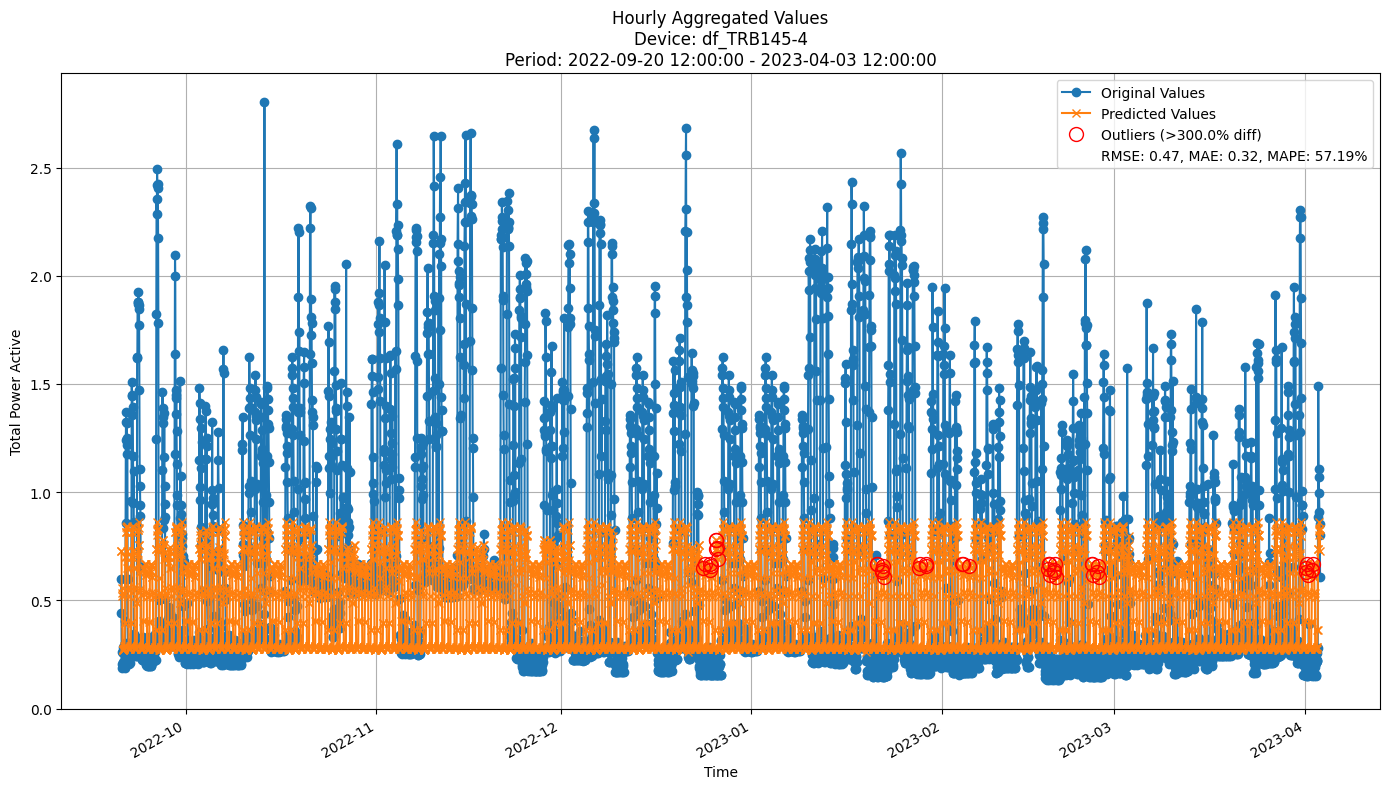

In [30]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

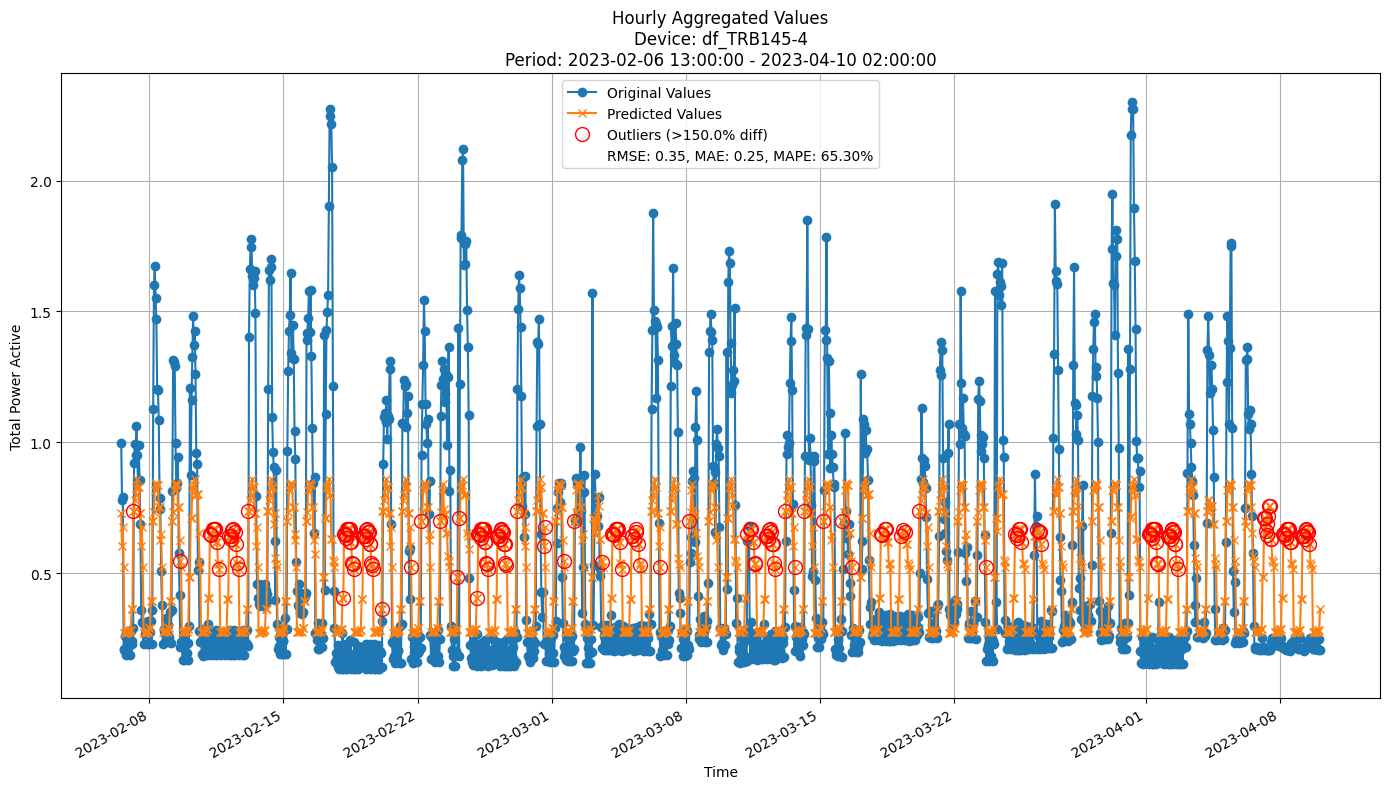

In [86]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [53]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 20
grace_period = 10
aggregation_method = "mean"
split_confidence = 0.5
tau = 0.01
max_depth = 40

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.5287
	MAE: 0.3563
	MAPE: 40.5830%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5287
	MAE: 0.3563
	MAPE: 40.5830%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 8.0346
	MAE: 6.7218
	MAPE: 35.4580%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 29.3918
	MAE: 25.4775
	MAPE: 27.0606%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 83.2779
	MAE: 63.6938
	MAPE: 36.0063%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.5738
	MAE: 0.4374
	MAPE: 85.4952%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5738
	MAE: 0.4374
	MAPE: 85.4952%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 8.0767
	MAE: 6.6229
	MAPE: 55.9769%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 15.9241
	MAE: 13.4351
	MAPE: 12.3991%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 34.1965
	MAE: 24.8709
	MAPE: 10.6121%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3218
	MAE: 0.2394
	MAPE: 61.4958%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3218
	MAE: 0.2394
	MAPE: 61.4958%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.0485
	MAE: 3.3642
	MAPE: 37.6714%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 5.2682
	MAE: 4.6462
	MAPE: 6.2143%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 6.0463
	MAE: 4.5461
	MAPE: 4.0860%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3444
	MAE: 0.2941
	MAPE: 110.6437%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3444
	MAE: 0.2941
	MAPE: 110.6437%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.5307
	MAE: 3.9904
	MAPE: 84.6573%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 22.1770
	MAE: 15.9617
	MAPE: 66.6653%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 31.9234
	MAE: 31.9234
	MAPE: 48.7136%


#### Results

In [56]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4275 ± 0.0299
	MAE: 0.3203 ± 0.0351
	MAPE: 0.7001 ± 0.1032
Hourly Metrics:
	RMSE: 0.4275 ± 0.0299
	MAE: 0.3203 ± 0.0351
	MAPE: 0.7001 ± 0.1032
Daily Metrics:
	RMSE: 6.5240 ± 0.5692
	MAE: 5.3126 ± 0.5065
	MAPE: 0.4961 ± 0.0460
Weekly Metrics:
	RMSE: 22.5864 ± 5.5229
	MAE: 18.4966 ± 4.1808
	MAPE: 0.1905 ± 0.0348
28_days Metrics:
	RMSE: 84.9266 ± 23.9419
	MAE: 72.5497 ± 19.3796
	MAPE: 0.1664 ± 0.0412

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.4218 ± 0.0919
	MAE: 0.3345 ± 0.0605
	MAPE: 0.8829 ± 0.2552
Hourly Metrics:
	RMSE: 0.4218 ± 0.0919
	MAE: 0.3345 ± 0.0605
	MAPE: 0.8829 ± 0.2552
Daily Metrics:
	RMSE: 6.2376 ± 1.3823
	MAE: 5.0632 ± 1.1601
	MAPE: 0.5896 ± 0.1700
Weekly Metrics:
	RMSE: 19.7865 ± 9.0414
	MAE: 16.2860 ± 8

#### Training plots
Plot only the last period of predictions

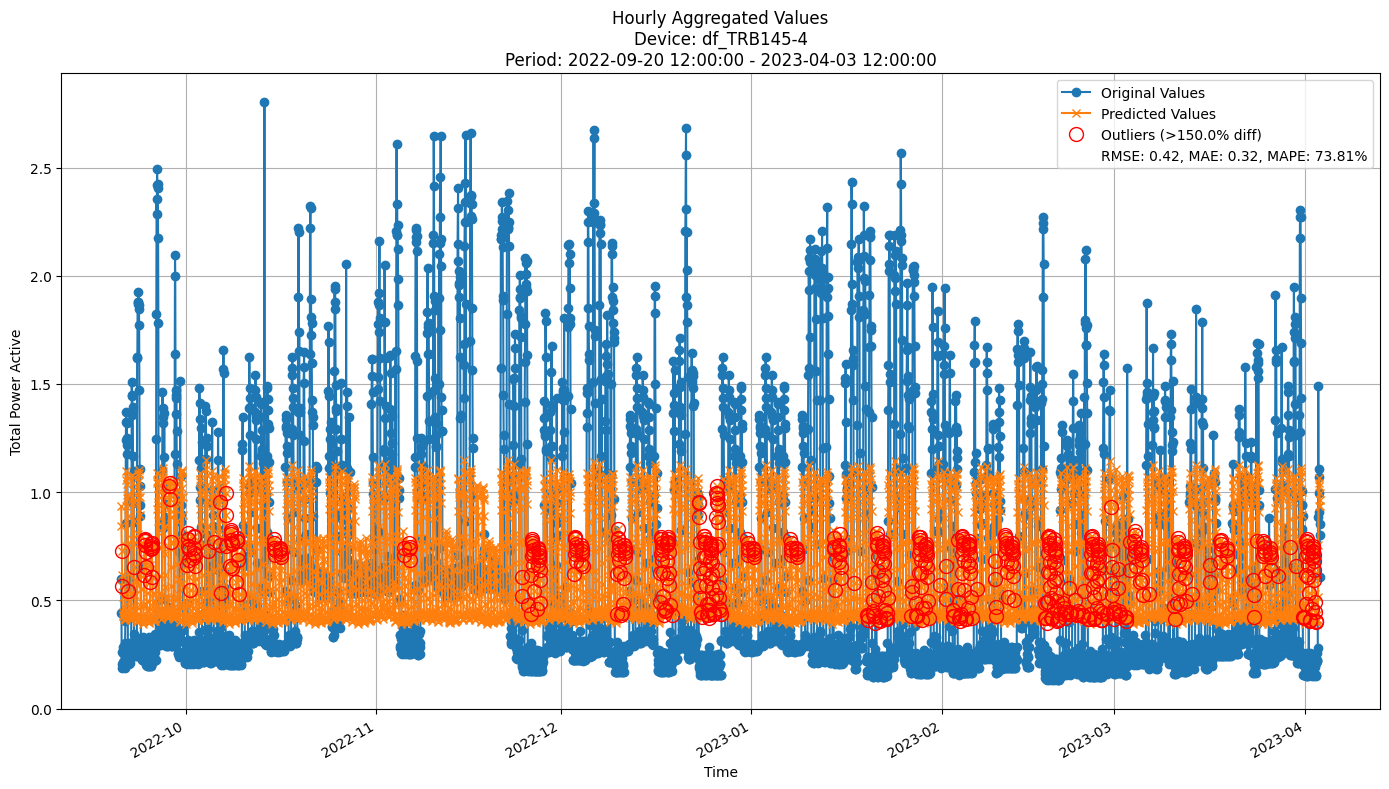

In [54]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

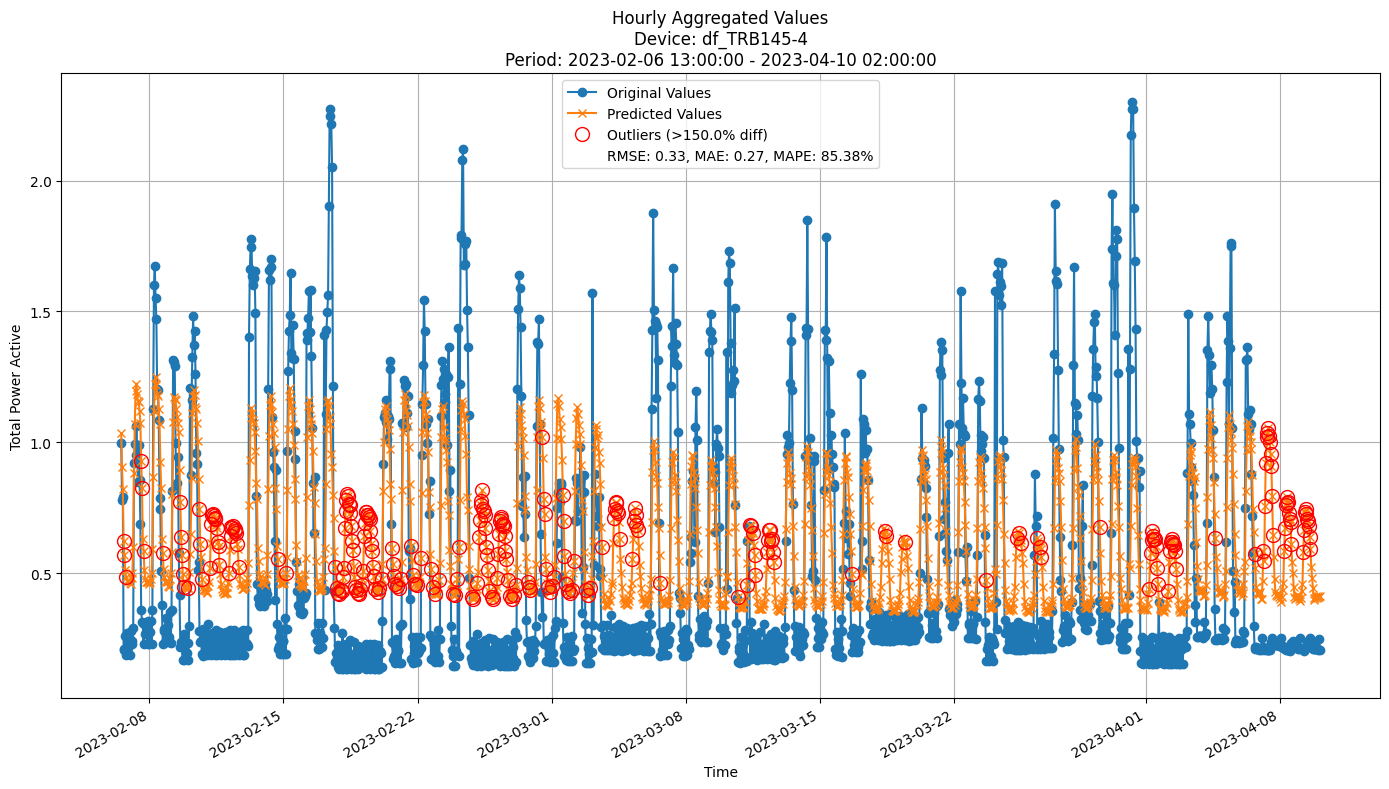

In [85]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [49]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
split_confidence = 0.5
n_trees = 10
depth = 20
grace_period = 10
incb = IncubationBoost(
    fastodt.FastODT,
    length=n_trees,
    incubationMode = "DEFAULT",
    baseLearnerOptions = (depth, grace_period, split_confidence, "hf"),
    verbose=False
    )

incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.4634
	MAE: 0.3337
	MAPE: 36.7546%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4634
	MAE: 0.3337
	MAPE: 36.7546%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 8.2690
	MAE: 6.9866
	MAPE: 33.7390%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 40.0540
	MAE: 36.6948
	MAPE: 34.2329%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 123.7446
	MAE: 91.7371
	MAPE: 37.7656%


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.4294
	MAE: 0.3393
	MAPE: 70.6321%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4294
	MAE: 0.3393
	MAPE: 70.6321%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 6.2264
	MAE: 5.3152
	MAPE: 48.1143%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.4578
	MAE: 8.6316
	MAPE: 15.6058%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 4.1501
	MAE: 3.7121
	MAPE: 23.8030%


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.3151
	MAE: 0.2164
	MAPE: 46.8955%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3151
	MAE: 0.2164
	MAPE: 46.8955%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.2323
	MAE: 2.6306
	MAPE: 24.3267%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 13.5670
	MAE: 11.7505
	MAPE: 22.4053%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 38.1183
	MAE: 29.3764
	MAPE: 33.7768%


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
5-Minute Metrics:
--------------------------------------------------
	RMSE: 0.2505
	MAE: 0.1744
	MAPE: 57.2040%
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2505
	MAE: 0.1744
	MAPE: 57.2040%
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.8803
	MAE: 2.2686
	MAPE: 42.8312%
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 12.6149
	MAE: 9.0745
	MAPE: 37.1536%
--------------------------------------------------
28_days Metrics:
--------------------------------------------------
	RMSE: 18.1490
	MAE: 18.1490
	MAPE: 27.6945%


#### Results

In [50]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, verbose=True)
print("\n\nValid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.3666 ± 0.0271
	MAE: 0.2667 ± 0.0334
	MAPE: 0.5349 ± 0.1422
Hourly Metrics:
	RMSE: 0.3666 ± 0.0271
	MAE: 0.2667 ± 0.0334
	MAPE: 0.5349 ± 0.1422
Daily Metrics:
	RMSE: 5.7098 ± 0.8056
	MAE: 4.6292 ± 0.9350
	MAPE: 0.3726 ± 0.1475
Weekly Metrics:
	RMSE: 27.3792 ± 9.0282
	MAE: 22.5545 ± 7.7964
	MAPE: 0.2304 ± 0.0819
28_days Metrics:
	RMSE: 106.8730 ± 39.5441
	MAE: 91.6160 ± 35.5702
	MAPE: 0.2036 ± 0.0893


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.3683 ± 0.0713
	MAE: 0.2832 ± 0.0722
	MAPE: 0.6825 ± 0.2708
Hourly Metrics:
	RMSE: 0.3683 ± 0.0713
	MAE: 0.2832 ± 0.0722
	MAPE: 0.6825 ± 0.2708
Daily Metrics:
	RMSE: 5.5512 ± 2.2171
	MAE: 4.7422 ± 2.0870
	MAPE: 0.4599 ± 0.2115
Weekly Metrics:
	RMSE: 25.4640 ± 15.1624
	MAE: 21.9601 ±

#### Train plots
Plot only the last period of predictions


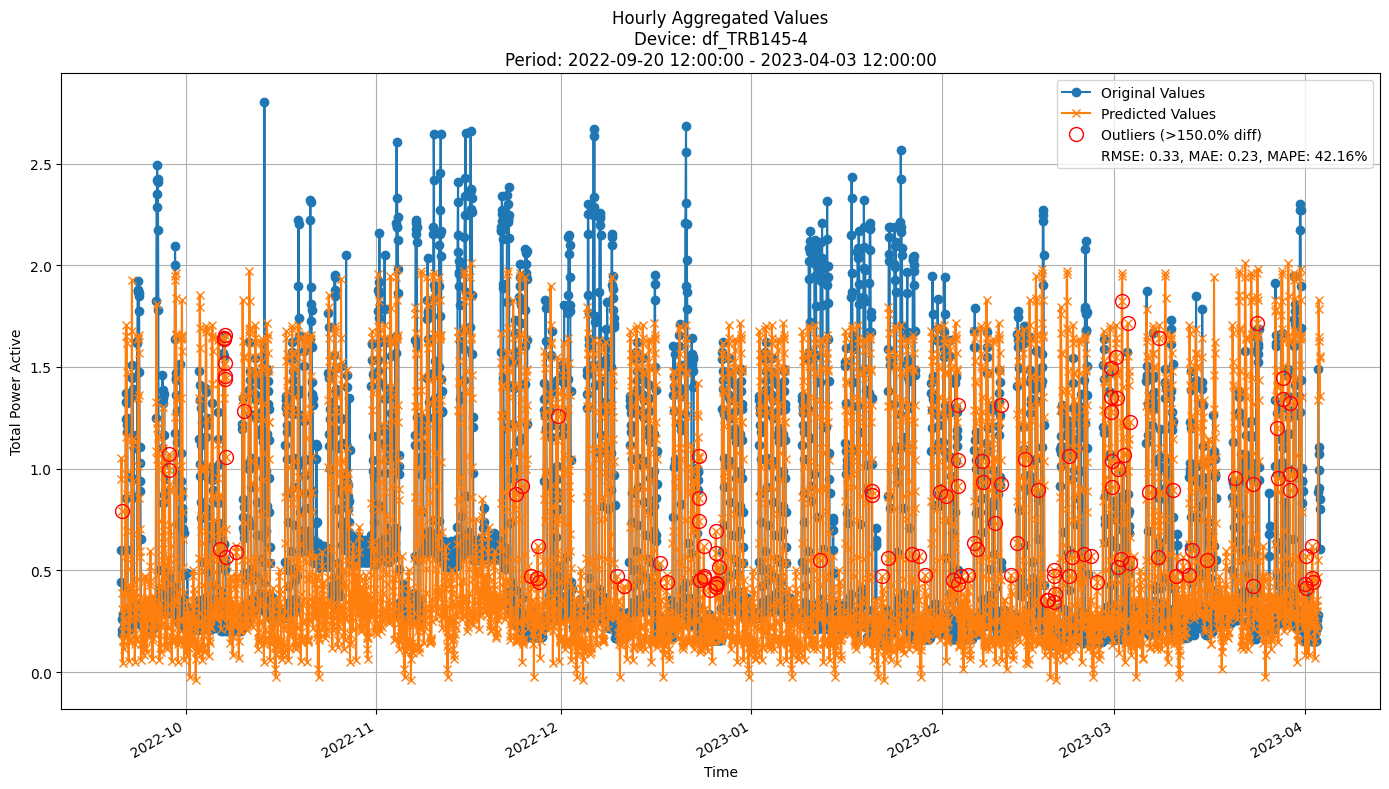

In [51]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

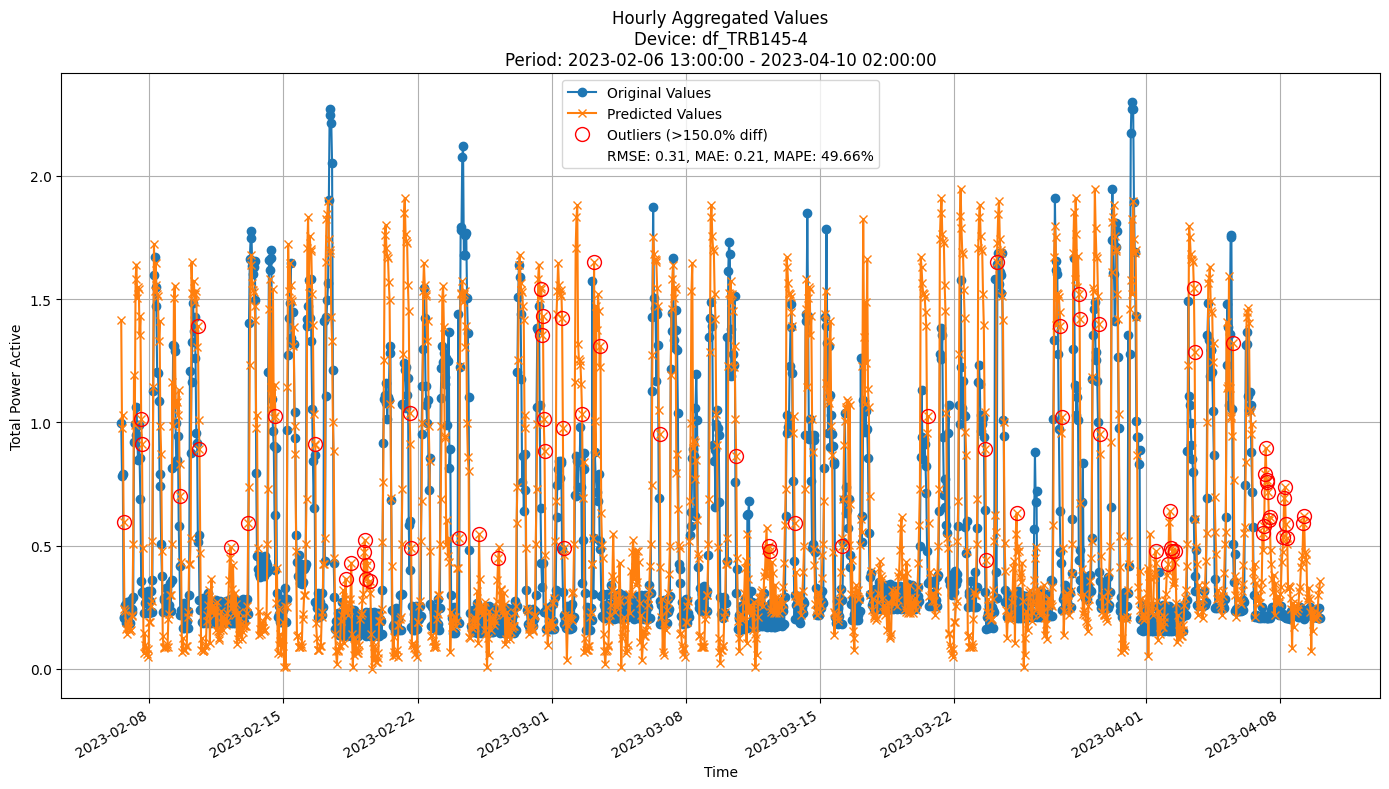

In [84]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            device_id=device_id,
                            outlier_threshold=1.5)

## Model Comparison

### Overall validation results

In [79]:
model_metrics = {
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": all_time_valid_metrics,
}

agg_level = "hourly"
metrics = ["rmse", "mae", "mape"]

device_ids = set()
for m in model_metrics.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_mape=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_mape:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_mape:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in model_metrics.items():
        if device_id in mdict and agg_level in mdict[device_id]:
            vals = mdict[device_id][agg_level]
            row = [model]
            for m in metrics:
                is_mape = (m == "mape")
                row.append(format_metric(vals.get(m, None), is_mape=is_mape))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {agg_level}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%)
0,GBDT,0.245 ± 0.062,0.170 ± 0.040,38.648 ± 6.302
1,RandomForest,0.222 ± 0.015,0.127 ± 0.009,22.147 ± 2.006
2,HoeffdingTree,0.293 ± 0.057,0.185 ± 0.043,33.554 ± 4.498
3,ARF_Hoeffding,0.265 ± 0.061,0.175 ± 0.042,36.376 ± 6.671
4,FastODT,0.448 ± 0.116,0.316 ± 0.077,60.613 ± 10.805
5,ARF_FastODT,0.422 ± 0.092,0.334 ± 0.060,88.291 ± 25.515
6,IncubationBoost,0.368 ± 0.071,0.283 ± 0.072,68.248 ± 27.083


### By-period validation results

In [82]:
model_period_metrics = {
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, model_period_metrics, agg_level, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    metric_name: "mape" or "rmse"
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in model_period_metrics.items():
            if device_id in mdict:
                if metric_name == "mape":
                    vals = [period[agg_level]["mape"]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[agg_level][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = "MAPE (%)" if metric_name == "mape" else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {agg_level} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label} (lower is better):")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.5872 ± 0.0517
	MAE: 0.4212 ± 0.0566
	MAPE: 0.6056 ± 0.1110
Hourly Metrics:
	RMSE: 0.5303 ± 0.0257
	MAE: 0.3428 ± 0.0191
	MAPE: 0.4909 ± 0.0518
Daily Metrics:
	RMSE: 9.7190 ± 1.1518
	MAE: 7.1517 ± 0.7297
	MAPE: 0.4024 ± 0.0227
Weekly Metrics:
	RMSE: 50.7311 ± 10.8158
	MAE: 41.8783 ± 8.9075
	MAPE: 0.3955 ± 0.1189
28_days Metrics:
	RMSE: 187.7911 ± 37.1665
	MAE: 158.9275 ± 34.0584
	MAPE: 0.4080 ± 0.1556

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
5_min Metrics:
	RMSE: 0.5295 ± 0.0419
	MAE: 0.3624 ± 0.0242
	MAPE: 0.6597 ± 0.0518
Hourly Metrics:
	RMSE: 0.4514 ± 0.0363
	MAE: 0.2711 ± 0.0671
	MAPE: 0.4916 ± 0.1163
Daily Metrics:
	RMSE: 7.4643 ± 0.7399
	MAE: 5.5142 ± 1.3481
	MAPE: 0.3901 ± 0.0609
Weekly Metrics:
	RMSE: 33.7915 ± 6.4465
	MAE: 29.1838 

#### MAPE

In [83]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=model_period_metrics,
    agg_level=agg_level,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,27.653,21.210,29.104,27.374,41.165,40.583,36.755,31.977714
Period 2,42.626,29.953,33.072,39.912,55.424,85.495,70.632,51.016286
Period 3,34.157,26.747,28.871,25.597,56.898,112.326,100.053,54.949857
Period 4,48.706,36.120,37.726,38.402,68.679,104.165,115.551,64.192714
Period 5,42.714,39.497,40.443,45.128,72.721,103.327,50.645,56.353571
Period 6,37.484,32.339,36.940,37.358,55.954,61.496,46.895,44.066571
Period 7,37.197,21.602,28.721,40.861,73.451,110.644,57.204,52.811429



Absolute gain/drop in MAPE (%) (lower is better):


,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,14.973,8.743,3.968,12.538,14.259,44.912,33.877,19.039
Period 3 - Period 2,-8.469,-3.206,-4.201,-14.315,1.474,26.831,29.421,3.934
Period 4 - Period 3,14.549,9.373,8.855,12.805,11.781,-8.161,15.498,9.243
Period 5 - Period 4,-5.992,3.377,2.717,6.726,4.042,-0.838,-64.906,-7.839
Period 6 - Period 5,-5.230,-7.158,-3.503,-7.770,-16.767,-41.831,-3.750,-12.287
Period 7 - Period 6,-0.287,-10.737,-8.219,3.503,17.497,49.148,10.309,8.745


#### RMSE

In [76]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=model_period_metrics,
    agg_level=agg_level,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost
Period 1,0.348,0.324,0.375,0.363,0.548,0.529,0.463
Period 2,0.308,0.287,0.357,0.325,0.618,0.574,0.429
Period 3,0.185,0.185,0.235,0.180,0.381,0.385,0.414
Period 4,0.269,0.269,0.289,0.271,0.569,0.456,0.395
Period 5,0.214,0.246,0.296,0.275,0.369,0.344,0.311
Period 6,0.226,0.239,0.299,0.250,0.347,0.322,0.315
Period 7,0.165,0.156,0.199,0.190,0.307,0.344,0.250



Absolute gain/drop in RMSE (lower is better):


,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost
Period 2 - Period 1,-0.040,-0.037,-0.018,-0.038,0.070,0.045,-0.034
Period 3 - Period 2,-0.123,-0.102,-0.122,-0.145,-0.237,-0.189,-0.015
Period 4 - Period 3,0.084,0.084,0.054,0.091,0.188,0.071,-0.019
Period 5 - Period 4,-0.055,-0.023,0.007,0.004,-0.200,-0.112,-0.084
Period 6 - Period 5,0.012,-0.007,0.003,-0.025,-0.022,-0.022,0.004
Period 7 - Period 6,-0.061,-0.083,-0.100,-0.060,-0.040,0.022,-0.065
